In [1]:
import torch 
import os 
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt

## Load sample from the data

In [2]:
path = os.path.dirname(os.getcwd())
print(path)
dfc2020_path = os.path.join(path, "Datasets/DFC_Public_Dataset")

/data/workspace/denqos/Projects/S2_Segmentation


In [3]:
s2_path = os.path.join(dfc2020_path, "sensors/train/s2") 
s2 = tiff.imread(os.path.join(s2_path, "ROIs0000_autumn_s2_BandarAnzali_p100.tif"))

In [4]:
# what is the dfc subset?
dfc_sample_path = os.path.join(dfc2020_path, "ROIs0000_spring/dfc_BlackForest") 
dfc_sample = tiff.imread(os.path.join(dfc_sample_path, "ROIs0000_spring_dfc_BlackForest_p100.tif"))

lc_sample_path = os.path.join(dfc2020_path, "ROIs0000_spring/lc_BlackForest")
lc_sample = tiff.imread(os.path.join(lc_sample_path, "ROIs0000_spring_lc_BlackForest_p100.tif"))

(256, 256) (256, 256, 4)
[1 2 4 5 6 7] [ 1  5 10 11 15]


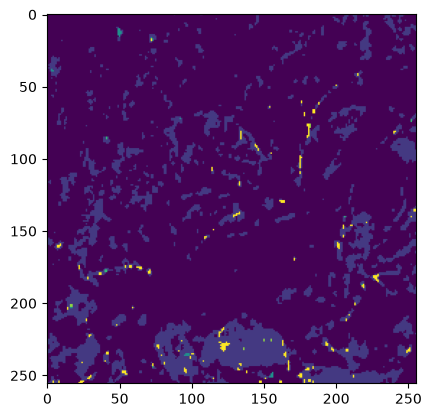

In [5]:
print(dfc_sample.shape, lc_sample.shape)
print(np.unique(dfc_sample), np.unique(lc_sample))

plt.imshow(dfc_sample)
plt.show()

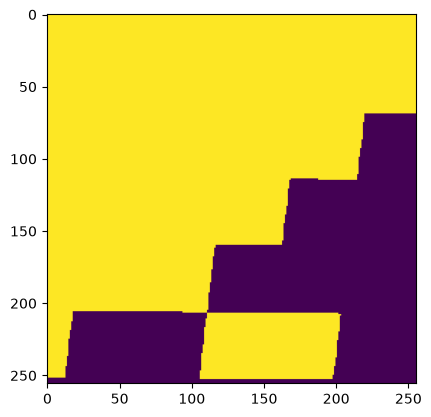

In [6]:
plt.imshow(lc_sample[..., 0])  # Displaying the first channel of the land-cover image
plt.show()

## Load the S2 data

In [7]:
import rasterio
from glob import glob

for f in glob("/data/workspace/denqos/Projects/S2_Segmentation/Datasets/DFC_Public_Dataset/sensors/dfc/*.tif")[:10]:
    with rasterio.open(f) as src:
        x = src.read(1)
    print(f, np.unique(x, return_counts=True))

In [11]:
def load_data(path, sensor_type="s2"):
    file_dirs = sorted(os.listdir(path))

    sensor_list = []
    for dir in file_dirs:
        if sensor_type in dir:
            sensor_file_path = os.path.join(path, dir)
            sensor = tiff.imread(sensor_file_path)
            sensor_list.append(sensor)
    return np.stack(sensor_list, axis=0)    

s2_samples = load_data(s2_path, sensor_type="s2")

In [12]:
# load the DFC samples
dfc_path = os.path.join(dfc2020_path, "sensors/train/dfc") 
print(dfc_path)
dfc_samples = load_data(dfc_path, sensor_type="dfc")

/data/workspace/denqos/Projects/S2_Segmentation/Datasets/DFC_Public_Dataset/sensors/train/dfc


In [13]:
print(s2_samples.shape)

# calculate mean and std for S2 
s2_samples = s2_samples.astype(np.float64)

print(s2_samples[..., 0].min(), s2_samples[..., 0].max())
print(s2_samples[..., 1].min(), s2_samples[..., 1].max())
print(s2_samples[..., 2].min(), s2_samples[..., 2].max())

mean = s2_samples.mean(axis=(0, 1, 2))
std  = s2_samples.std(axis=(0, 1, 2))

print(f"{mean = }")
print(f"{std = }")


(5144, 256, 256, 3)
1.0 24462.0
1.0 21768.0
1.0 21955.0
mean = array([ 742.18204123,  900.92913371, 1001.47387247])
std = array([457.93828837, 303.53038521, 261.91184758])


In [14]:
# standardize the S2 samples
s2 = (s2_samples - mean) / std
print(s2.min(), s2.max())

for i, band in enumerate(["R", "G", "B"]):
    x = s2_samples[..., i]

    print(
        band,
        "min =", x.min(),
        "max =", x.max(),
        "mean =", x.mean(),
        "std =", x.std(),
        "p1 =", np.percentile(x, 1),
        "p99 =", np.percentile(x, 99),
    )

-3.8198878047192277 80.00220807638678
R min = 1.0 max = 24462.0 mean = 742.1820412275395 std = 457.93828837328016 p1 = 252.0 p99 = 2368.0
G min = 1.0 max = 21768.0 mean = 900.929133713338 std = 303.5303852139764 p1 = 474.0 p99 = 1899.0
B min = 1.0 max = 21955.0 mean = 1001.473872471004 std = 261.9118475789453 p1 = 656.0 p99 = 1823.0


In [153]:
threshold = 3000
total_pixels = s2_samples.shape[0] * s2_samples.shape[1] * s2_samples.shape[2]

count_R = (s2_samples[:, :, :, 0] > threshold).sum()
count_G = (s2_samples[:, :, :, 1] > threshold).sum()
count_B = (s2_samples[:, :, :, 2] > threshold).sum()

print("R:", count_R / total_pixels * 100, "%")
print("G:", count_G / total_pixels * 100, "%")
print("B:", count_B / total_pixels * 100, "%")

R: 0.20856071222996453 %
G: 0.1231966270814602 %
B: 0.10762103423360347 %


## Histogram

In [44]:
names = ["R", "G", "B"]
MAXV = 24462
counts = np.zeros((3, MAXV + 1), dtype=np.int64)

chunk = 256  # patches per chunk, lower this if memory is tight
for i in range(0, s2_samples.shape[0], chunk):
    block = s2_samples[i:i + chunk]
    for c in range(3):
        v = block[..., c].ravel().astype(np.int64)
        counts[c] += np.bincount(v, minlength=MAXV + 1)

In [46]:
total = counts.sum(axis=1)
for c, n in enumerate(names):
    above = counts[c, 10001:].sum() / total[c]
    print(f"{n}: >10000 {above:.4%} | ==10000 {counts[c,10000]/total[c]:.4%} "
          f"| ==0 {counts[c,0]/total[c]:.4%} | ==1 {counts[c,1]/total[c]:.4%}")

R: >10000 0.0003% | ==10000 0.0000% | ==0 0.0000% | ==1 0.0000%
G: >10000 0.0002% | ==10000 0.0000% | ==0 0.0000% | ==1 0.0000%
B: >10000 0.0002% | ==10000 0.0000% | ==0 0.0000% | ==1 0.0000%


In [49]:
sat_frac = np.concatenate([
    (s2_samples[i:i+chunk] == MAXV).any(axis=-1).mean(axis=(1, 2))
    for i in range(0, s2_samples.shape[0], chunk)
])
print("patches with any saturated pixel:", (sat_frac > 0).mean())
print("patches with >10% saturated pixels:", (sat_frac > 0.10).mean())

patches with any saturated pixel: 0.00019440124416796267
patches with >10% saturated pixels: 0.0


The reflectance value of 99.0 percentile is 2368


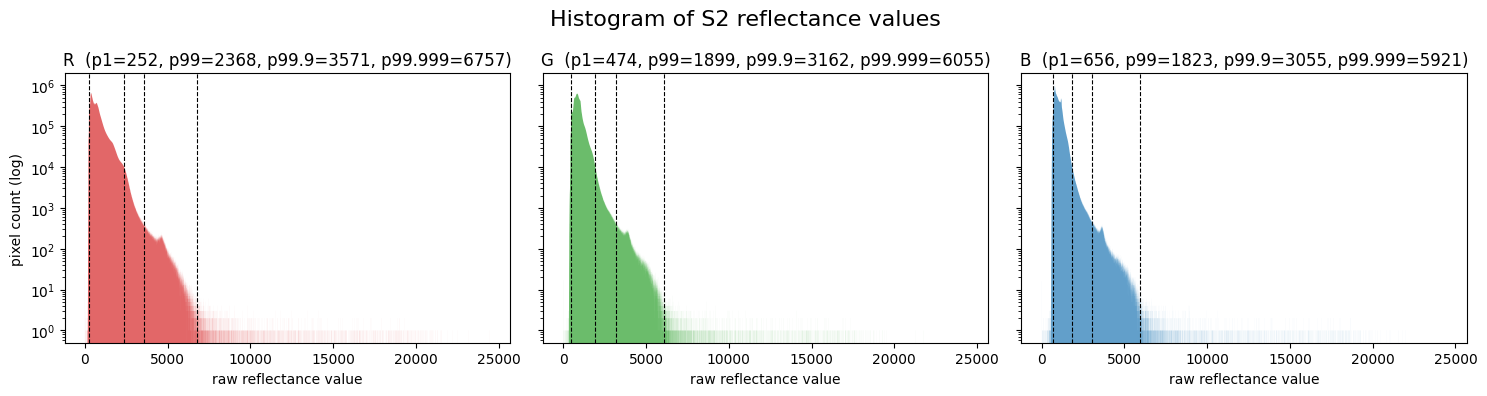

In [152]:
import matplotlib.pyplot as plt

def plt_histogram(cdf, counts, names, MAXV, percentile=99):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    edges = np.arange(MAXV + 2)

    for c, (ax, col) in enumerate(zip(axes, ["tab:red", "tab:green", "tab:blue"])):
        ax.stairs(counts[c], edges, color=col, fill=True, alpha=0.7)
        ax.set_yscale("log")
        p1, p99, p99_9, p99_999 = np.searchsorted(cdf[c], [0.01, percentile / 100, 0.999, 0.99999])
        ax.axvline(p1, ls="--", c="k", lw=0.8)
        ax.axvline(p99, ls="--", c="k", lw=0.8)
        ax.axvline(p99_9, ls="--", c="k", lw=0.8)
        ax.axvline(p99_999, ls="--", c="k", lw=0.8)
        ax.set_title(f"{names[c]}  (p1={p1}, p{percentile}={p99}, p99.9={p99_9}, p99.999={p99_999})")
        ax.set_xlabel("raw reflectance value")
    axes[0].set_ylabel("pixel count (log)")
    fig.suptitle(f"Histogram of S2 reflectance values", fontsize=16)
    plt.tight_layout()
    plt.show() 

cdf = np.cumsum(counts, axis=1) / total[:, None]

# percentile = 99.0
vmax = int(max(np.searchsorted(cdf[c], 0.99) for c in range(3)))
print(f"The reflectance value of 99.0 percentile is {vmax}")
plt_histogram(cdf, counts, names, MAXV, percentile=99)
    

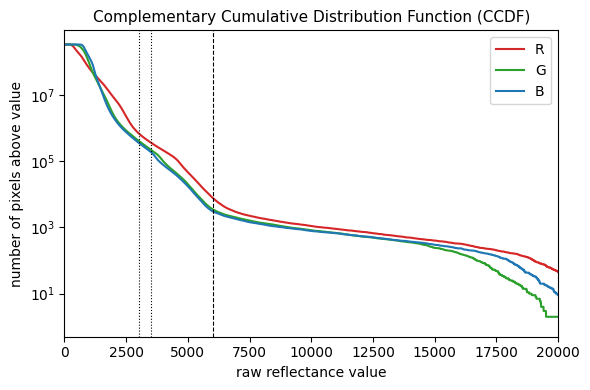

In [151]:
names = ["R", "G", "B"]
colors = ["tab:red", "tab:green", "tab:blue"]

# number of pixels with value > v, for every v
n_above = total[:, None] - np.cumsum(counts, axis=1)    # shape (3, MAXV+1)

fig, ax = plt.subplots(figsize=(6, 4))

# left: log y-axis, absolute counts
for c in range(3):
    ax.plot(n_above[c], color=colors[c], label=names[c])
ax.set_yscale("log")
ax.set_ylim(0.5, None)          # 0.5 so that "0 pixels" doesn't break the log axis
ax.set_title("Complementary Cumulative Distribution Function (CCDF)", fontsize=11)
ax.set_xlim(0, 20000)
ax.set_xlabel("raw reflectance value")
ax.set_ylabel("number of pixels above value")
ax.axvline(3000, ls=":", c="k", lw=0.8)
ax.axvline(3500, ls=":", c="k", lw=0.8)
ax.axvline(6000, ls="--", c="k", lw=0.8)
ax.legend()
plt.tight_layout()
plt.show()


### Decide on how to clip the data

Three possibilities:

- The 99 percentile -> around reflectance=3500
- The full range of the data -> around reflectance=6000
- Convention for displaying Sentinel-2 true color -> reflectance=3000

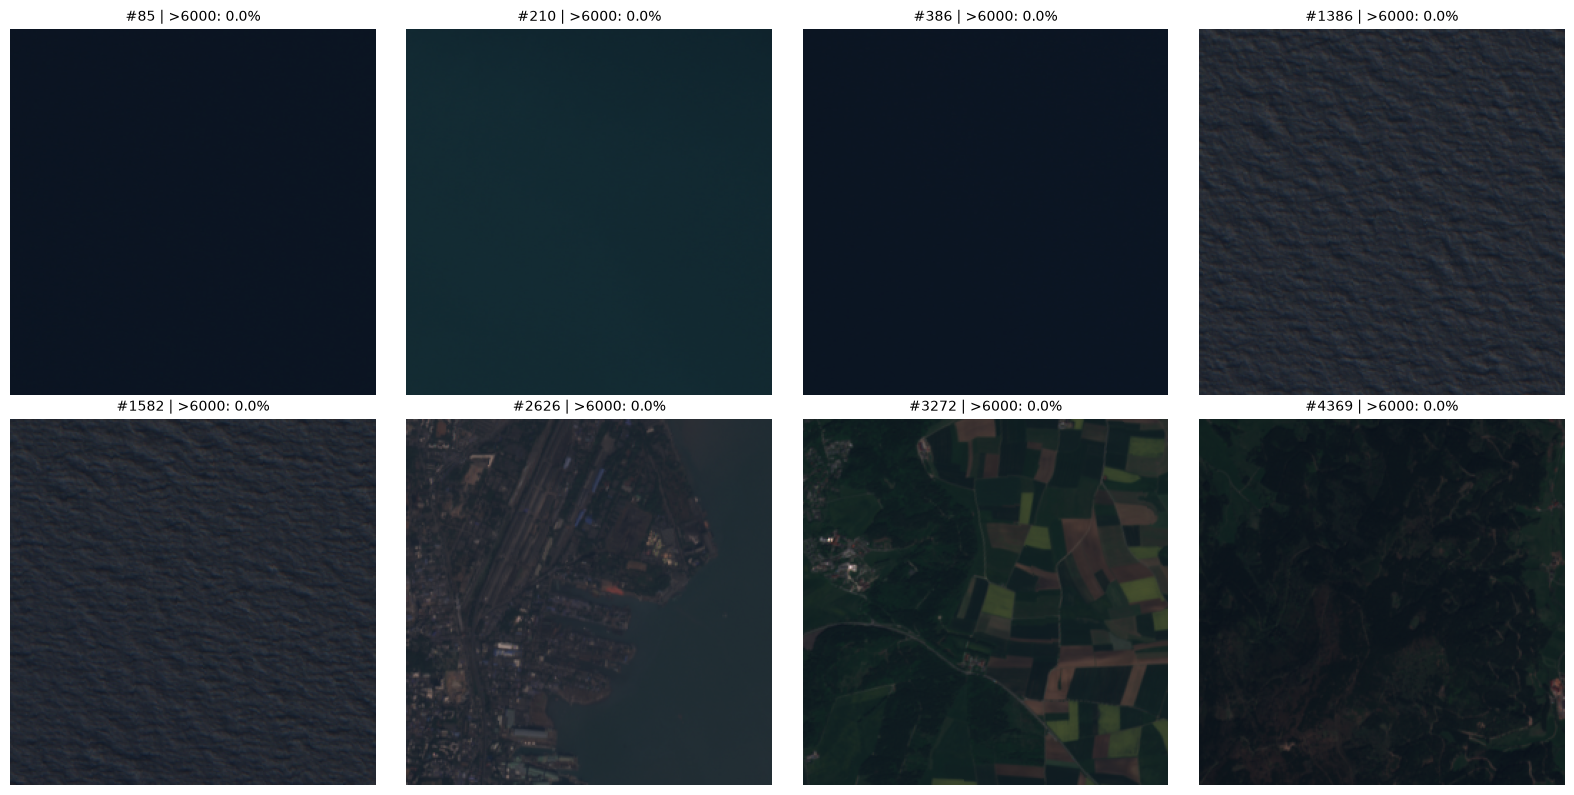

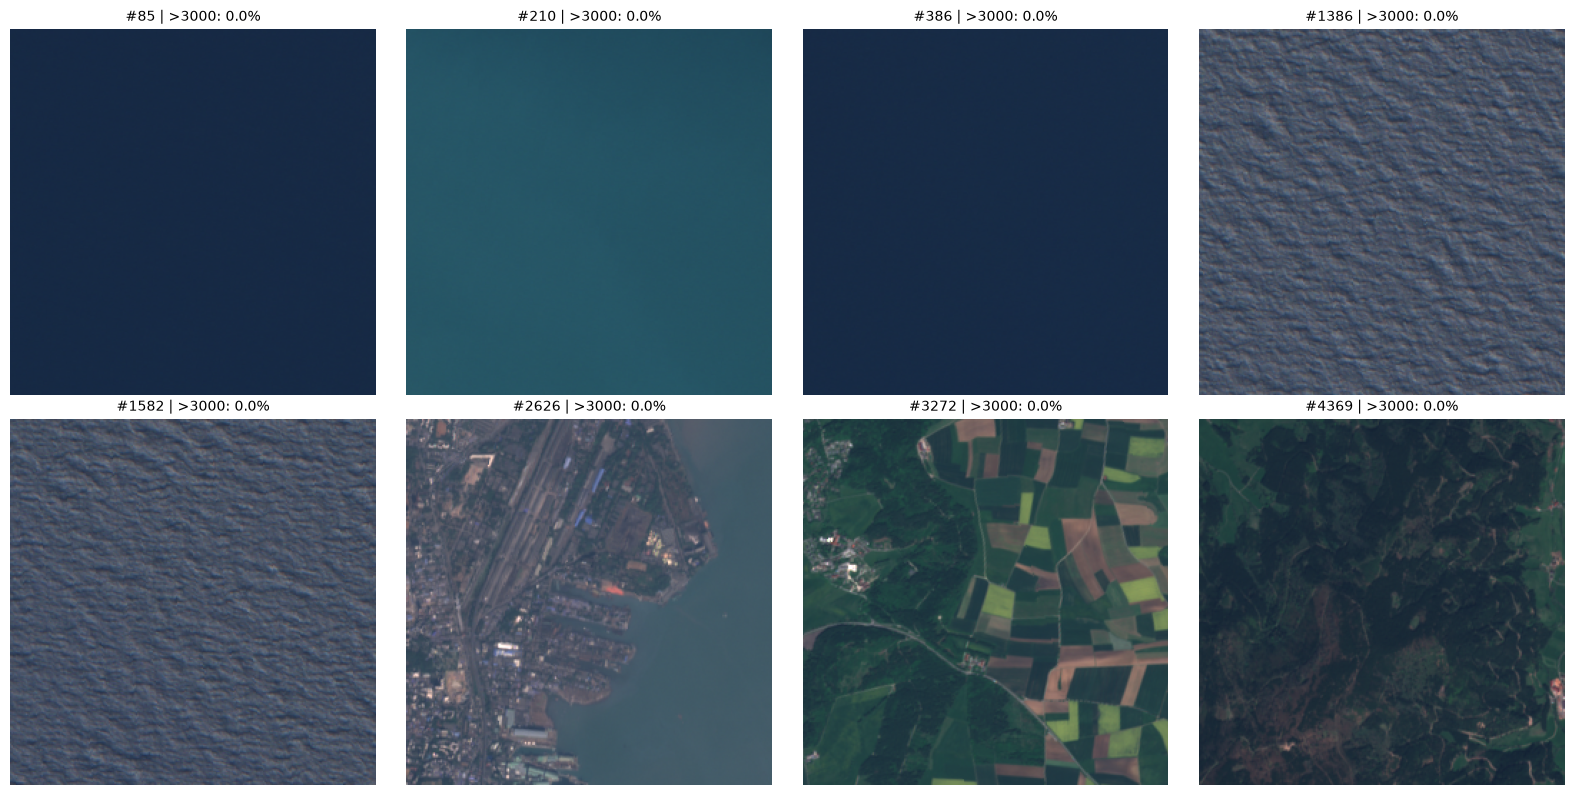

In [24]:
# plot the data
def to_rgb(img, vmax=3000):
    """Raw reflectance (R, G, B order) -> displayable [0, 1] image."""
    return np.clip(img.astype(np.float32) / vmax, 0, 1)

def plot_images(idx, s2_samples, vmax=3000):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, i in zip(axes.ravel(), idx):
        img = s2_samples[i]
        frac_bright = (img > vmax).any(axis=-1).mean()
        ax.imshow(to_rgb(img, vmax=vmax))
        ax.set_title(f"#{i} | >{vmax}: {frac_bright:.1%}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(0)
idx = np.sort(rng.choice(s2_samples.shape[0], size=8, replace=False))
plot_images(idx, s2_samples, vmax=6000)

plot_images(idx, s2_samples, vmax=3000)



In [25]:
# Obtain the 8 brightest patches with reflectance above 6000 or 3000
bright_frac = np.array([(s2_samples[i] > 3000).any(axis=-1).mean() for i in range(s2_samples.shape[0])])
idx = np.argsort(bright_frac)[-8:][::-1]   

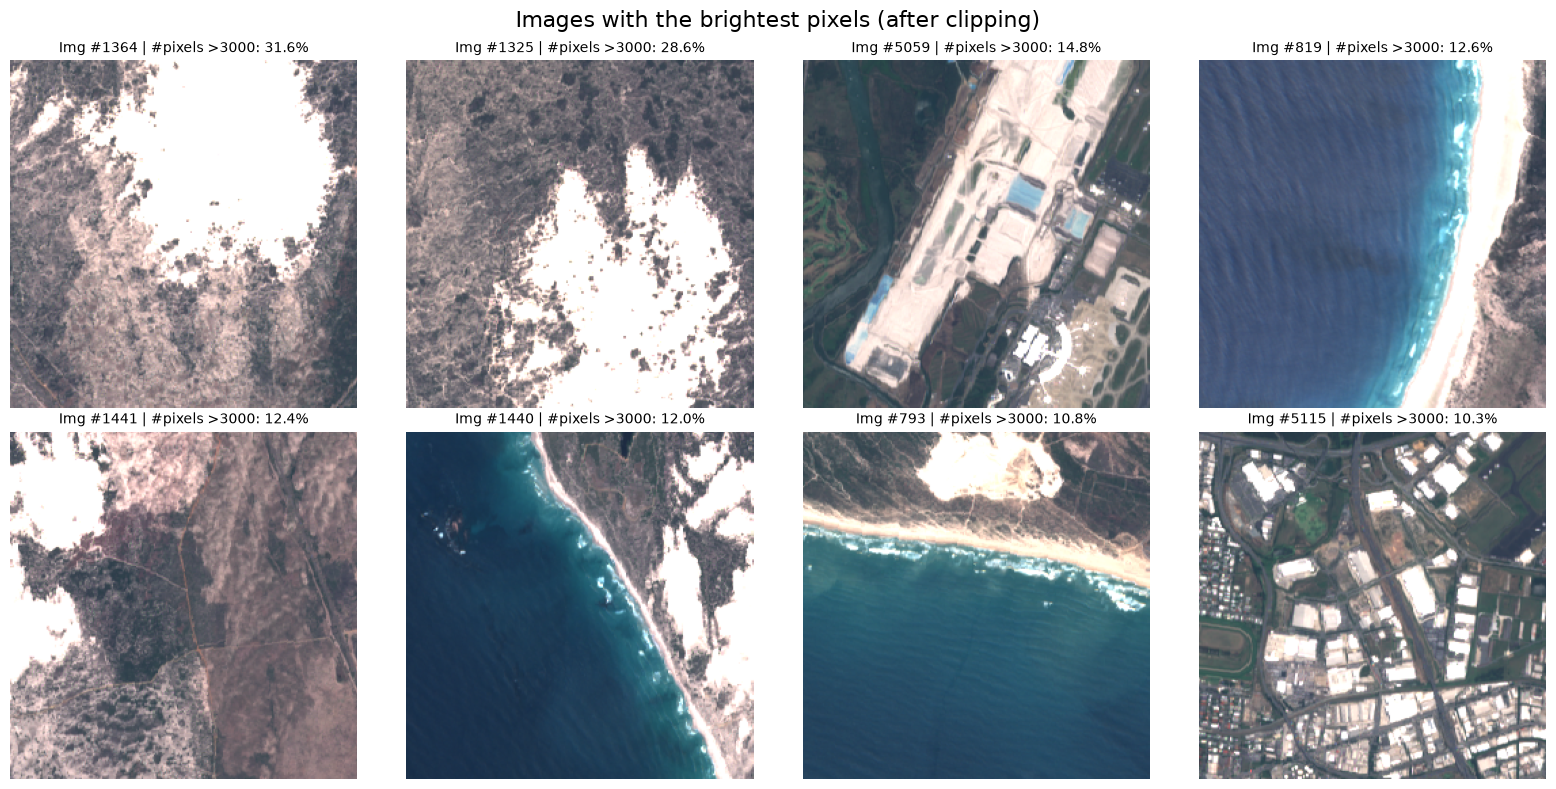

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), idx):
    img = s2_samples[i]
    frac_bright = (img > 3000).any(axis=-1).mean()
    ax.imshow(to_rgb(img, vmax=3000))
    ax.set_title(f"Img #{i} | #pixels >3000: {frac_bright:.1%}", fontsize=10)
    ax.axis("off")
fig.suptitle(f"Images with the brightest pixels (after clipping)", fontsize=16)
plt.tight_layout()
plt.show()

### Clipping and Normalizing the Data

In [ ]:
# Step 1: handle very bright areas. Set Threshold=3000 since it is the common value used for displaying S2 images
clip_threshold = 3000
s2_clipped = np.clip(s2_samples, 0.0, clip_threshold) #.astype(np.float32)

mean = s2_clipped.mean(axis=(0, 1, 2))
std  = s2_clipped.std(axis=(0, 1, 2))

print(f"{mean = }")
print(f"{std = }")


mean = array([ 740.54718457,  900.030319  , 1000.71999455])
std = array([446.71191971, 294.84727152, 253.65544069])


In [28]:
# Step 2: standardize the S2 samples
s2 = (s2_clipped - mean) / std
print(s2.min(), s2.max())

for i, band in enumerate(["R", "G", "B"]):
    x = s2_clipped[..., i]

    print(
        band,
        "min =", x.min(),
        "max =", x.max(),
        "mean =", x.mean(),
        "std =", x.std(),
        "p1 =", np.percentile(x, 1),
        "p99 =", np.percentile(x, 99)
    )

-3.94125192761215 7.881873142724054
R min = 1.0 max = 3000.0 mean = 740.5471845689124 std = 446.7119197137058 p1 = 252.0 p99 = 2368.0
G min = 1.0 max = 3000.0 mean = 900.0303189973253 std = 294.84727152589977 p1 = 474.0 p99 = 1899.0
B min = 1.0 max = 3000.0 mean = 1000.7199945523987 std = 253.65544068720433 p1 = 656.0 p99 = 1823.0


In [20]:
S2_CLIP_THRESHOLD = 3000
S2_MEAN = np.array(
    [740.54718457, 900.030319, 1000.71999455],     # [mean_R, mean_G, mean_B]
    dtype=np.float32
)

S2_STD = np.array(
    [460.21289232, 301.78994503, 260.39637968],       # [std_R, std_G, std_B]
    dtype=np.float32
)
# labels indices
RAW_TO_TRAIN = {
            1: 0,
            2: 1,
            4: 2,
            5: 3,
            6: 4,
            7: 5,
            9: 6,
            10: 7,
        }
IGNORE_INDEX = 255
def prepare_s2(s2):
    "S2 contains reflectance values from the sensor"
    s2 = s2.astype(np.float32, copy=False)

    # handle very bright areas. Set Threshold=3000 since it is the common value used for displaying S2 images

    np.clip(s2, 0.0, S2_CLIP_THRESHOLD, out=s2)

    # standardization (normalization)
    s2 = (s2 - S2_MEAN) / S2_STD

    # (N, H, W, C) -> (N, C, H, W)
    s2 = np.moveaxis(s2, -1, 1) if s2.ndim == 4 else np.moveaxis(s2, -1, 0)

    print(f"S2 data normalized: min = {s2.min():.4f}, max = {s2.max():.4f}")
    return s2


def prepare_labels(mask):
    # class 3 and 8 are removed from the dataset, so remap the labels to a continuous range of integers
    if mask.ndim == 3:
        mask = mask[..., 0]

    target = np.full(mask.shape, IGNORE_INDEX, dtype=np.uint8)
    for raw_id, train_id in RAW_TO_TRAIN.items():
        target[mask == raw_id] = train_id

    return target

In [ ]:
IGNORE_INDEX=255
def plot_processed_images(idx, ds, target):
    fig, axes = plt.subplots(2, 8, figsize=(24, 6))
    for col, i in enumerate(idx):
        img = ds[i]
        axes[0, col].imshow(s2_to_rgb(img))
        axes[0, col].set_title(f"#{i}", fontsize=10)
        lab = np.ma.masked_equal(target[i], IGNORE_INDEX)   # hide ignored pixels
        axes[1, col].imshow(lab, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
        for r in (0, 1):
            axes[r, col].axis("off")
    plt.tight_layout()
    plt.show()

def s2_to_rgb(x, normalized=True, gamma=1.0):
    """x: (3, H, W) array or tensor from the dataset -> (H, W, 3) float in [0, 1]."""
    x = np.asarray(x, dtype=np.float32)
    x = np.moveaxis(x, 0, -1)                 # CHW -> HWC
    if normalized:
        x = x * S2_STD + S2_MEAN              # undo standardization -> clipped reflectance
    x = np.clip(x / S2_CLIP_THRESHOLD, 0, 1)            # clip value is 3000, the usual display stretch
    return x ** gamma                         # gamma < 1 brightens dark scenes

(5144, 256, 256, 3)
S2 data normalized: min = -3.8392, max = 7.6778
(5144, 3, 256, 256)


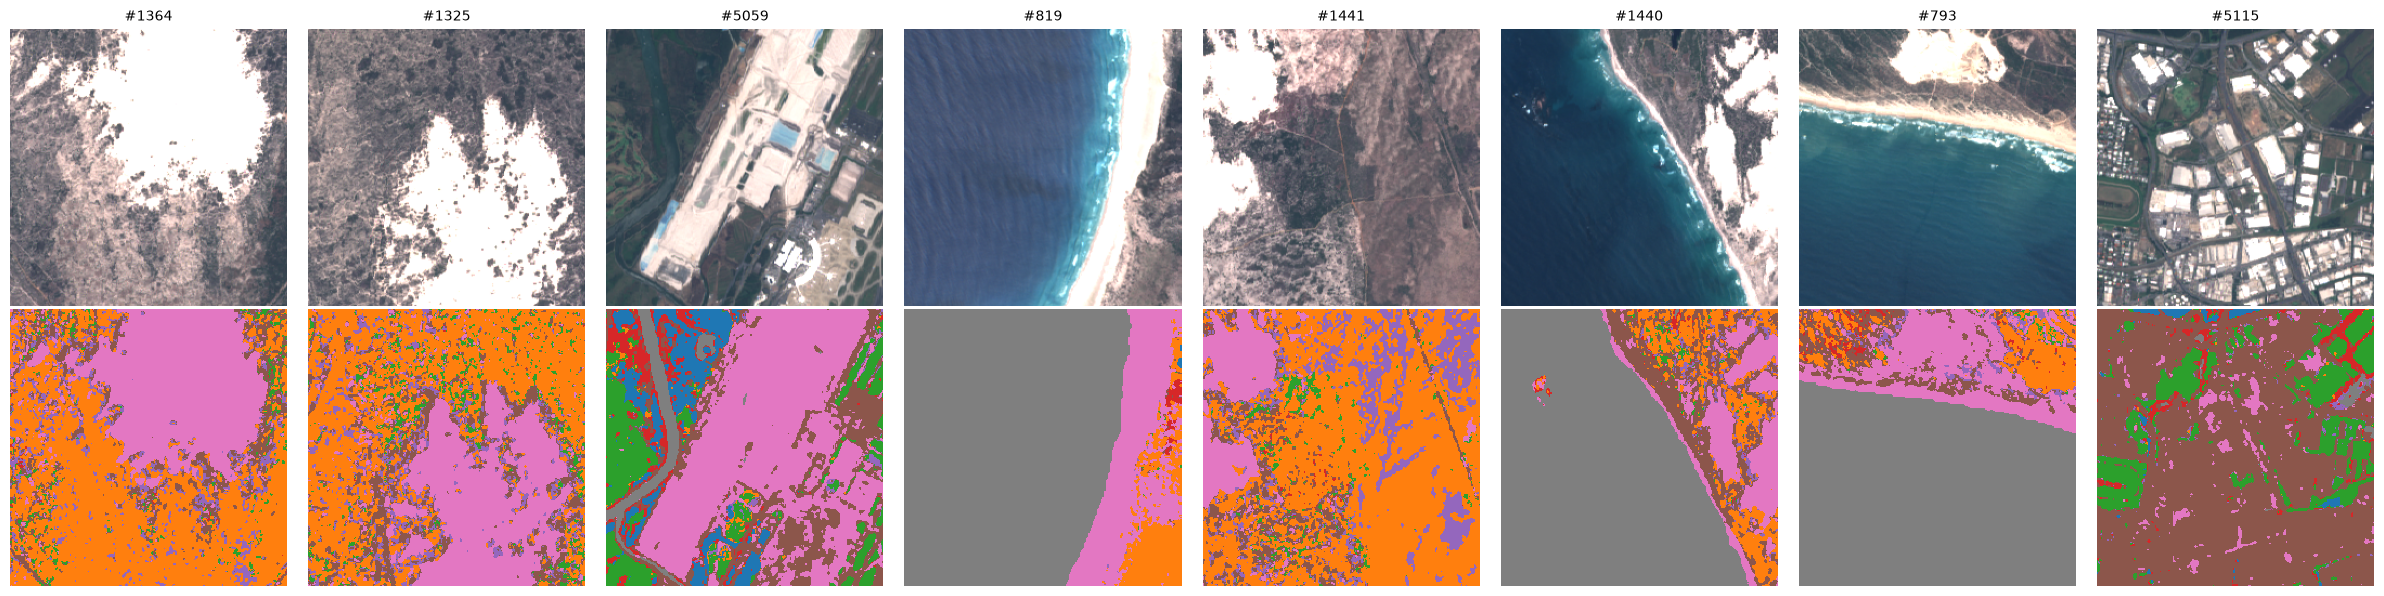

In [27]:
#rng = np.random.default_rng(0)
#idx = np.sort(rng.choice(s2_samples.shape[0], size=8, replace=False))

print(s2_samples.shape)

processed_s2 = prepare_s2(s2_samples)
processed_labels = np.stack([prepare_labels(lc) for lc in dfc_samples], axis=0)
print(processed_s2.shape)
plot_processed_images(idx, processed_s2, processed_labels)

## SEN12MS 

In [ ]:
ms_path_s2 = "/data/datasets/SEN12MS/ROIs1158_spring/s2_115/ROIs1158_spring_s2_115_p030.tif"
sen12ms_s2 = tiff.imread(ms_path_s2)
sen12ms_s2.shape

In [ ]:
ms_path_lc = "/data/datasets/SEN12MS/ROIs1158_spring/lc_001/ROIs1158_spring_lc_001_p030.tif"
sen12ms_lc = tiff.imread(ms_path_lc)
sen12ms_lc.shape

In [ ]:
ms_path_s1 = "/data/datasets/SEN12MS/ROIs1158_spring/s1_115/ROIs1158_spring_s1_115_p030.tif"
sen12ms_s1 = tiff.imread(ms_path_s1)
print(sen12ms_s1.max(), sen12ms_s1.min())


In [ ]:
for f in glob("/data/datasets/SEN12MS/sensors_v2/s1/*.tif")[:10]:
    with rasterio.open(f) as src:
        x = src.read(1)
    print(x.max(), x.min())

-5.1969943 -21.946577
-5.0146456 -20.045582
-2.718996 -26.30828
-3.762057 -23.055477
4.4006585e-15 -30.265936
0.0 -26.433395
0.0 -22.44535
-4.331985 -20.741606
-4.0407076 -24.39797
-3.800422 -29.225485


/data/workspace/denqos/miniconda3/envs/ldm/lib/python3.8/site-packages/rasterio/__init__.py:304: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


In [80]:
x_all = []
for f in glob("/data/datasets/SEN12MS/sensors_v2/s2/*.tif")[:100]:
    with rasterio.open(f) as src:
        x = src.read(1)
    print(x.max(), x.min())
    x_all.append(x)
x_allll = np.stack(x_all, axis=0)
print(x_allll.mean(axis=(0, 1, 2), dtype=np.float64))
print(x_allll.std(axis=(0, 1, 2), dtype=np.float64))

2059 796
3259 179
759 378
2243 1118
6888 710
3170 349
6093 603
5545 407
2092 238
1116 346
473 338
2113 510
616 324
6788 356
2329 399
4868 3026
2856 718
3067 437
6101 310
3096 999
4400 314
1347 210
4589 348
16550 413
1329 633
1510 602
8999 294
2101 783
2278 331
2857 388
5325 313
4213 510
1805 328
2768 728
14332 319
2568 395
2004 448
1062 291
4196 350
2957 401
1912 726
3687 408
3428 417
6372 305
2854 715
1606 429
1736 184
4558 722
4392 422
2959 468
3178 1231
1766 411
499 319
1192 322
3823 749
3623 424
2716 725
9689 388
6714 417
3220 1071
3321 319
4345 610
12813 6002
9938 403
1743 312
3383 309
3917 366
1494 516
3379 382
5812 327
2506 770
2596 491
1406 380
8420 1963
1874 357
1013 388
5971 412
2842 248
3567 663
3056 715
6490 380
2135 448
4279 370
2829 355
1288 565
1112 340
9798 498
1574 639
5882 352
2778 478
9252 2200
5494 397
3348 413
2301 579
2434 748
2975 386
3065 1064
3000 322
3880 1423
3681 392
1168.5300505065918
1284.5673109628517
